# Predicción del éxito de cosecha de manzanas con un robot humanoide

**Proyecto final — Ciencia de Datos e Inteligencia Artificial aplicados a la Mecatrónica (UTEC, 2026/2)**

Un robot Unitree G1 con mano Dex3 cosecha manzanas: la cámara de la cabeza (Intel RealSense D435i) detecta la
fruta, una política de aprendizaje por refuerzo lleva el brazo hasta ella, la mano la agarra, se desprende del
pedúnculo y se lleva a una canasta. No todos los intentos terminan bien: el brazo puede no llegar, el agarre
puede quedar flojo, el pedúnculo puede no cortarse, o la fruta puede caerse en el camino.

**Pregunta:** *antes de intentar*, con lo que el robot ya sabe (dónde está la manzana y qué vecinas ve la
cámara), ¿se puede predecir

1. si el intento terminará con la manzana en la canasta? (clasificación binaria), y
2. en qué etapa fallará? (clasificación multiclase)

Una buena predicción sirve para elegir qué manzana intentar primero y para no gastar tiempo y batería en
intentos con baja probabilidad de éxito.

**Datos:** generados en simulación (Isaac Lab) con la misma secuencia y las mismas políticas que corre el robot
real (`ml_project/recolectar_dataset.py`). Cada fila es un intento sobre un árbol aleatorio. La validación
también es en simulación (no es posible validar en el robot real en el plazo del proyecto).

In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, learning_curve,
                                     cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             brier_score_loss, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)
import sklearn, matplotlib

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
DATOS = os.environ.get("ML_DATOS", "datos")          # carpeta con los CSV de recolectar_dataset.py
FIG = os.environ.get("ML_FIG", "figuras")             # figuras para el reporte
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, nombre + ".png"), dpi=200, bbox_inches="tight")

print("python numpy pandas sklearn matplotlib:", np.__version__, pd.__version__, sklearn.__version__,
      matplotlib.__version__)

python numpy pandas sklearn matplotlib: 2.1.3 2.3.1 1.8.0 3.9.2


## 1. Carga de los datos

Se leen todos los CSV de `datos/` (una corrida de simulación por semilla). Se descartan los intentos cuya
manzana objetivo no está entera dentro del cuadro de la cámara: el robot real no intentaría una manzana que no
ve.

In [2]:
archivos = sorted(glob.glob(os.path.join(DATOS, "*.csv")))
df = pd.concat([pd.read_csv(f) for f in archivos], ignore_index=True)
print(f"{len(archivos)} archivo(s), {len(df)} intentos, semillas {sorted(df.semilla.unique())}")
n0 = len(df)
df = df[df.objetivo_visible == 1].copy()
print(f"descartados por objetivo fuera del cuadro de la cámara: {n0 - len(df)}")
df.head()

3 archivo(s), 2604 intentos, semillas [np.int64(0), np.int64(1), np.int64(2)]
descartados por objetivo fuera del cuadro de la cámara: 41


,episodio,semilla,env,t_inicio_s,objetivo_visible,yaw_cintura_deg,x_hombro_m,y_hombro_m,z_hombro_m,dist_hombro_m,...,n_vecinos_vis_15cm,n_vecinos_vis_debajo,n_manzanas_arbol,n_vecinos_ocultos,exito,etapa,estado_fallo,motivo,error_alcance_cm,duracion_s
0,0,0,2,0.5,1,10.95145,0.33081,-0.09507,-0.45541,0.57085,...,0,0,4,2,0,alcance,approach,the hand ended 12.3 cm from the apple goal (ti...,12.30,13.76
1,1,0,14,0.5,1,-12.04602,0.32199,-0.12348,-0.41175,0.53709,...,0,0,2,1,0,alcance,approach,the hand ended 6.4 cm from the apple goal (tim...,6.40,15.92
2,2,0,13,0.5,1,11.94342,0.35975,0.00567,-0.07349,0.36723,...,0,2,4,1,0,agarre,grasp,nothing between the fingers after the close,1.59,16.00
3,3,0,8,0.5,1,-7.09053,0.31492,-0.08892,-0.38849,0.50794,...,0,0,5,3,0,agarre,grasp,nothing between the fingers after the close,0.77,16.10
4,4,0,3,0.5,1,9.29073,0.32979,-0.17209,-0.28076,0.46605,...,0,0,3,2,0,agarre,grasp,nothing between the fingers after the close,1.82,17.68


In [3]:
print("Resultado de los intentos (etapa donde terminó):")
t = df.etapa.value_counts()
display(pd.DataFrame({"intentos": t, "proporción": (t / len(df)).round(3)}))
print(f"tasa de éxito global: {df.exito.mean():.1%}")

Resultado de los intentos (etapa donde terminó):


,intentos,proporción
etapa,,
exito,954,0.372
agarre,700,0.273
desprendimiento,496,0.194
alcance,222,0.087
transporte,127,0.050
retorno,55,0.021
deposito,9,0.004


tasa de éxito global: 37.2%


## 2. Análisis de las características

### 2.1 Naturaleza de cada variable

Todas las entradas se conocen **antes** del intento (el robot las obtiene de la cámara y de su propio estado).
Las variables que solo existen en simulación o que describen el resultado (`error_alcance_cm`, `duracion_s`,
`motivo`, `n_vecinos_ocultos`, `n_manzanas_arbol`) **no** se usan como entradas: usarlas sería una fuga de
información (*data leakage*). La distancia al tronco tampoco se usa: en el robot real todavía no se estima de
forma confiable.

Dos columnas del CSV se descartan por cómo está construida la simulación: `radio_manzana_m` (el simulador fija
un radio por entorno al arrancar, así que solo actuaría como identificador del entorno) y `n_vecinos_vis_15cm`
(los vecinos se colocan a 10 cm o más de superficie a superficie, por lo que siempre vale 0).

In [4]:
ENTRADAS = ["yaw_cintura_deg", "x_hombro_m", "y_hombro_m", "z_hombro_m", "dist_hombro_m", "dist_horiz_m",
            "azimut_deg", "elevacion_deg", "u_px", "v_px", "prof_cam_m",
            "n_vecinos_vis", "dist_vecino_min_m", "vec_dx_m", "vec_dy_m", "vec_dz_m",
            "n_vecinos_vis_debajo", "hay_vecino_vis"]
DISCRETAS = {"n_vecinos_vis", "n_vecinos_vis_debajo", "hay_vecino_vis"}
DESCRIPCION = {
    "yaw_cintura_deg": "giro de la cintura con que se ve el árbol",
    "x_hombro_m": "manzana respecto al hombro derecho, hacia adelante (marco del torso)",
    "y_hombro_m": "manzana respecto al hombro, hacia la izquierda",
    "z_hombro_m": "manzana respecto al hombro, hacia arriba",
    "dist_hombro_m": "distancia 3D hombro-manzana",
    "dist_horiz_m": "distancia horizontal hombro-manzana",
    "azimut_deg": "ángulo horizontal de la manzana visto desde el hombro",
    "elevacion_deg": "ángulo vertical de la manzana visto desde el hombro",
    "u_px": "columna del centro de la manzana en la imagen (424 px)",
    "v_px": "fila del centro de la manzana en la imagen (240 px)",
    "prof_cam_m": "profundidad medida por la cámara",
    "radio_manzana_m": "radio de la manzana",
    "n_vecinos_vis": "manzanas vecinas que la cámara ve enteras",
    "dist_vecino_min_m": "distancia al vecino visible más cercano (sin vecino: 0.5 m)",
    "vec_dx_m": "vecino más cercano respecto al objetivo, adelante (sin vecino: 0)",
    "vec_dy_m": "vecino más cercano respecto al objetivo, izquierda (sin vecino: 0)",
    "vec_dz_m": "vecino más cercano respecto al objetivo, arriba (sin vecino: 0)",
    "n_vecinos_vis_15cm": "vecinos visibles a menos de 15 cm",
    "n_vecinos_vis_debajo": "vecinos visibles debajo del objetivo (a < 15 cm en horizontal)",
    "hay_vecino_vis": "1 si la cámara ve al menos un vecino",
}

# sin vecino visible: distancia "lejos" (0.5 m) y desplazamientos 0, con un indicador aparte
df["hay_vecino_vis"] = df.n_vecinos_vis.gt(0).astype(int)
df["dist_vecino_min_m"] = df.dist_vecino_min_m.fillna(0.5)
for c in ["vec_dx_m", "vec_dy_m", "vec_dz_m"]:
    df[c] = df[c].fillna(0.0)

tabla = pd.DataFrame({
    "descripción": [DESCRIPCION[c] for c in ENTRADAS],
    "tipo": ["discreta" if c in DISCRETAS else "continua" for c in ENTRADAS],
    "rol": "independiente (entrada)",
})
tabla.index = ENTRADAS
tabla.loc["exito"] = ["1 = manzana depositada en la canasta", "discreta (binaria)", "dependiente (salida 1)"]
tabla.loc["etapa"] = ["etapa donde terminó el intento", "discreta (categórica)", "dependiente (salida 2)"]
tabla

,descripción,tipo,rol
yaw_cintura_deg,giro de la cintura con que se ve el árbol,continua,independiente (entrada)
x_hombro_m,"manzana respecto al hombro derecho, hacia adel...",continua,independiente (entrada)
y_hombro_m,"manzana respecto al hombro, hacia la izquierda",continua,independiente (entrada)
z_hombro_m,"manzana respecto al hombro, hacia arriba",continua,independiente (entrada)
dist_hombro_m,distancia 3D hombro-manzana,continua,independiente (entrada)
dist_horiz_m,distancia horizontal hombro-manzana,continua,independiente (entrada)
azimut_deg,ángulo horizontal de la manzana visto desde el...,continua,independiente (entrada)
elevacion_deg,ángulo vertical de la manzana visto desde el h...,continua,independiente (entrada)
u_px,columna del centro de la manzana en la imagen ...,continua,independiente (entrada)
v_px,fila del centro de la manzana en la imagen (24...,continua,independiente (entrada)


In [5]:
df[ENTRADAS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
yaw_cintura_deg,2563.0,0.050,8.559,-14.998,-7.247,-0.106,7.363,14.993
x_hombro_m,2563.0,0.338,0.040,0.227,0.312,0.336,0.363,0.479
y_hombro_m,2563.0,-0.068,0.065,-0.239,-0.114,-0.077,-0.027,0.183
z_hombro_m,2563.0,-0.260,0.102,-0.474,-0.349,-0.257,-0.190,-0.002
dist_hombro_m,2563.0,0.445,0.068,0.245,0.391,0.439,0.502,0.627
dist_horiz_m,2563.0,0.351,0.040,0.232,0.325,0.351,0.376,0.494
azimut_deg,2563.0,-11.224,10.638,-35.451,-19.021,-12.930,-4.484,27.238
elevacion_deg,2563.0,-35.297,11.564,-53.696,-44.624,-37.694,-28.155,-0.293
u_px,2563.0,336.733,37.328,182.267,314.567,344.090,364.251,401.806
v_px,2563.0,159.015,42.628,28.568,132.630,168.569,194.612,221.080


### 2.2 Análisis individual: distribución de cada variable según el resultado

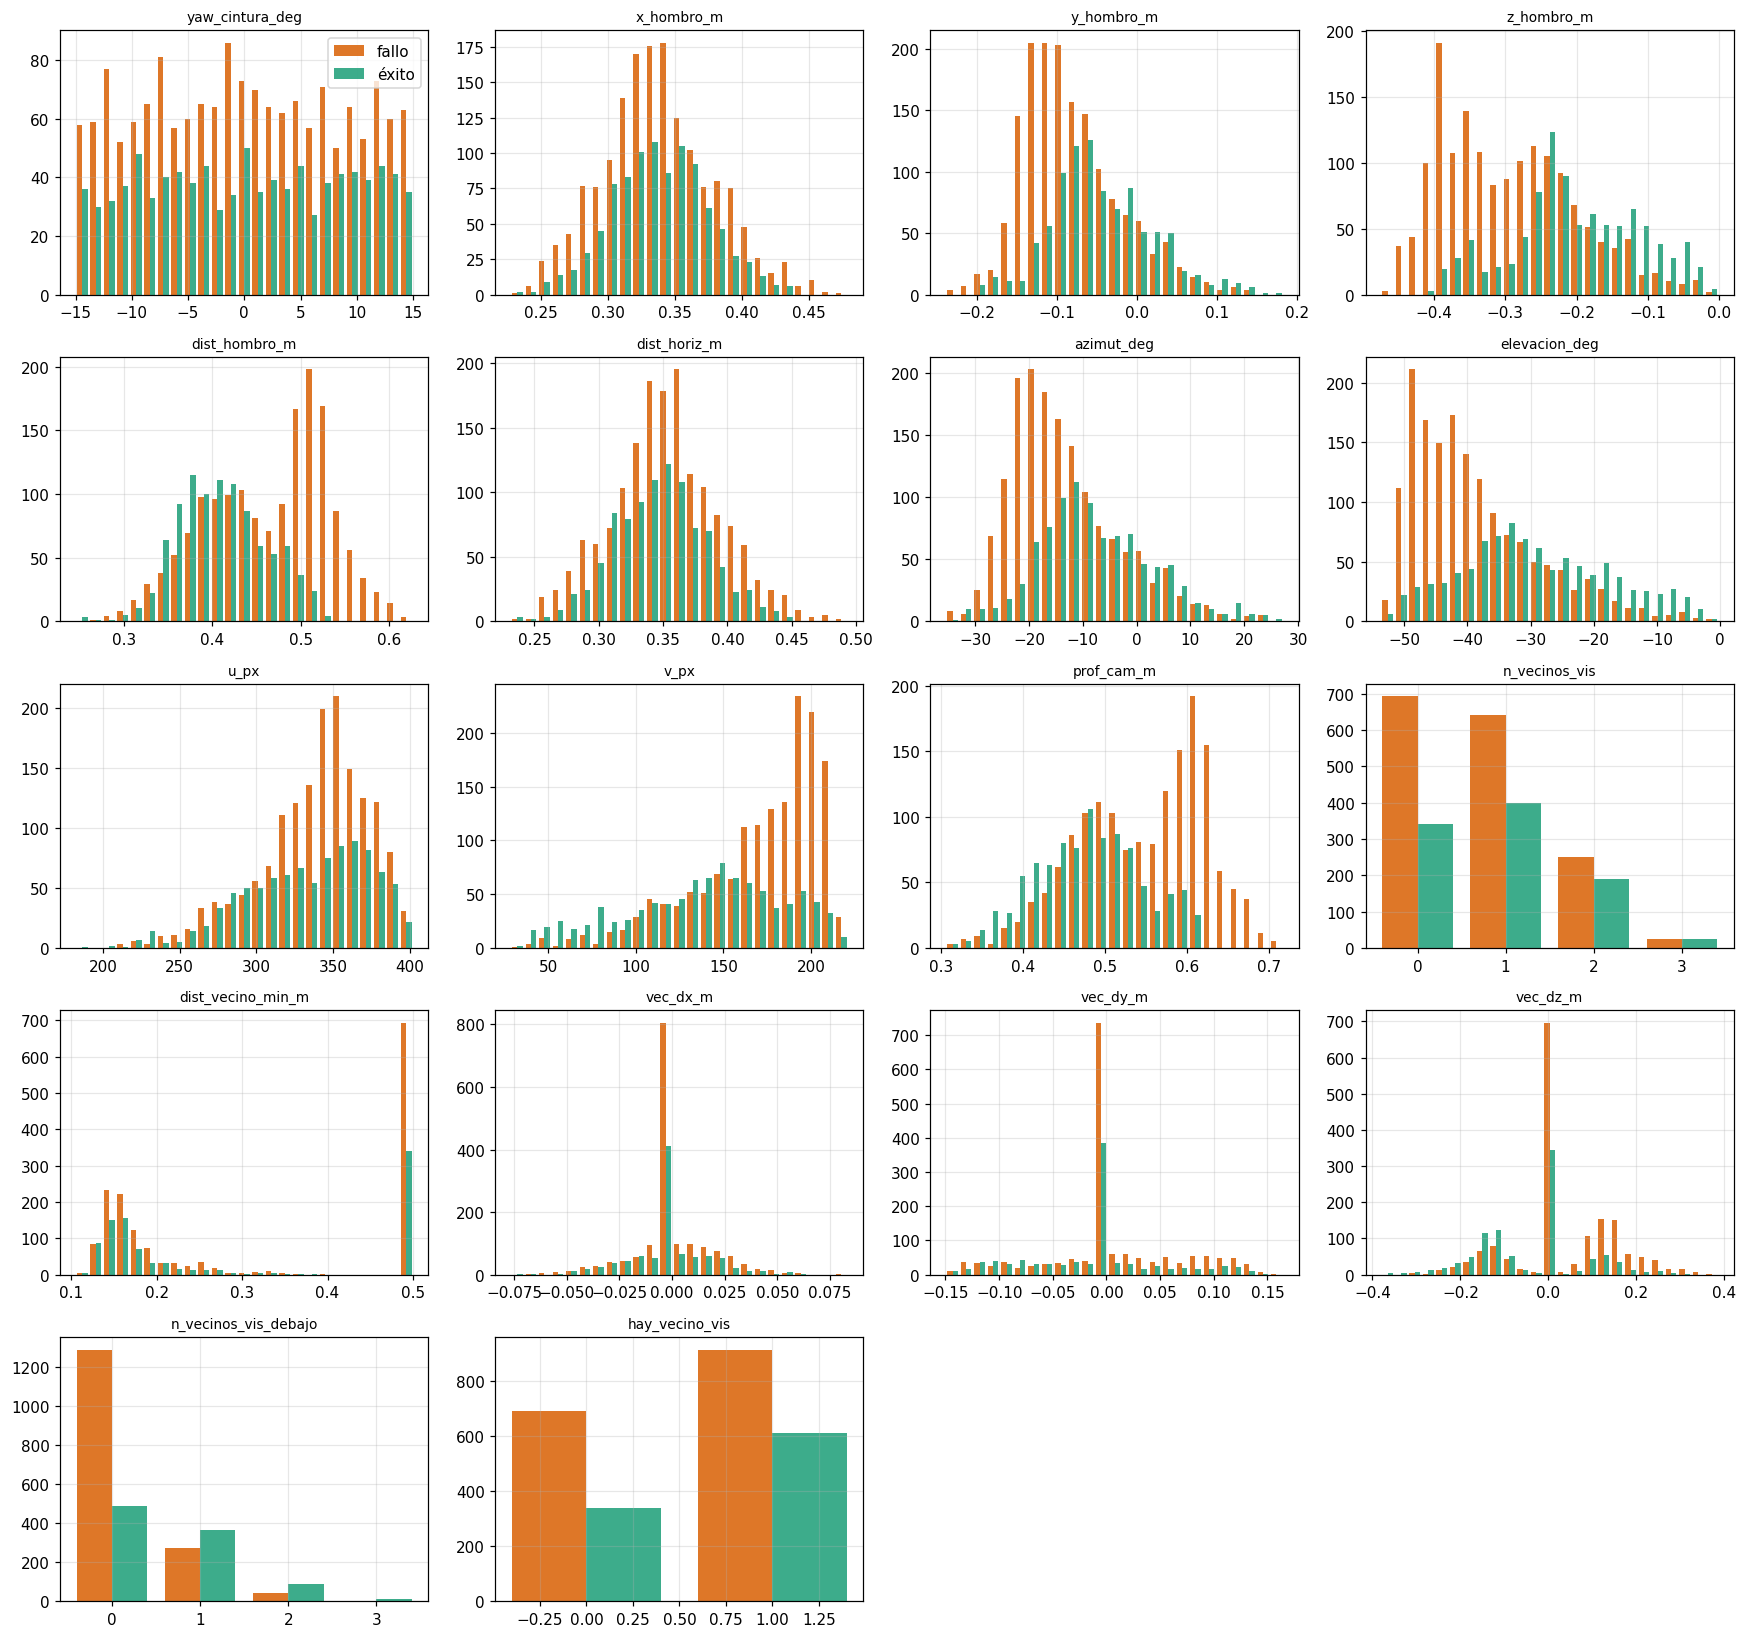

In [6]:
n = len(ENTRADAS)
cols = 4
fig, axs = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(16, 3.0 * np.ceil(n / cols)))
for ax, c in zip(axs.flat, ENTRADAS):
    ok, ko = df.loc[df.exito == 1, c], df.loc[df.exito == 0, c]
    bins = np.arange(df[c].min() - 0.5, df[c].max() + 1.5) if c in DISCRETAS else 25
    ax.hist([ko, ok], bins=bins, label=["fallo", "éxito"], color=["#d95f02", "#1b9e77"], alpha=0.85)
    ax.set_title(c, fontsize=9)
for ax in list(axs.flat)[n:]:
    ax.axis("off")
axs.flat[0].legend()
guardar("distribuciones")
plt.show()

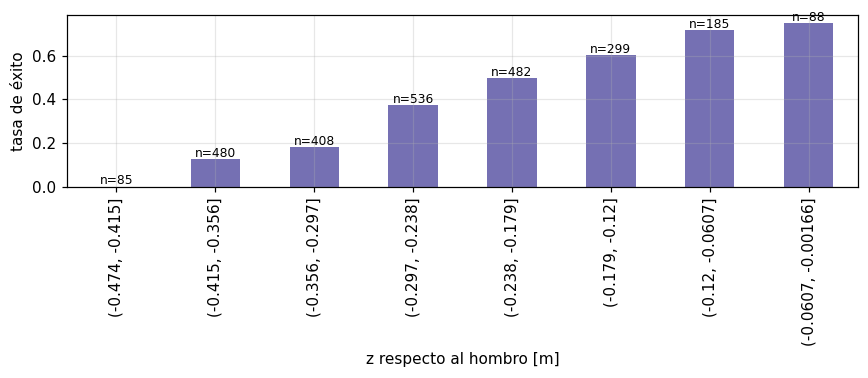

In [7]:
# tasa de éxito por altura de la manzana respecto al hombro (en el robot real la altura fue decisiva)
bins = pd.cut(df.z_hombro_m, bins=8)
g = df.groupby(bins, observed=True).exito.agg(["mean", "count"])
ax = g["mean"].plot(kind="bar", figsize=(8, 3.5), color="#7570b3")
ax.set_ylabel("tasa de éxito"); ax.set_xlabel("z respecto al hombro [m]")
for k, (m, c) in enumerate(g.values):
    ax.text(k, m + 0.01, f"n={int(c)}", ha="center", fontsize=8)
guardar("exito_vs_altura")
plt.show()

### 2.3 Análisis colectivo: mapa de correlaciones

Correlación de Pearson entre las entradas y con la salida binaria (para una salida binaria, la correlación de
Pearson es la correlación punto-biserial).

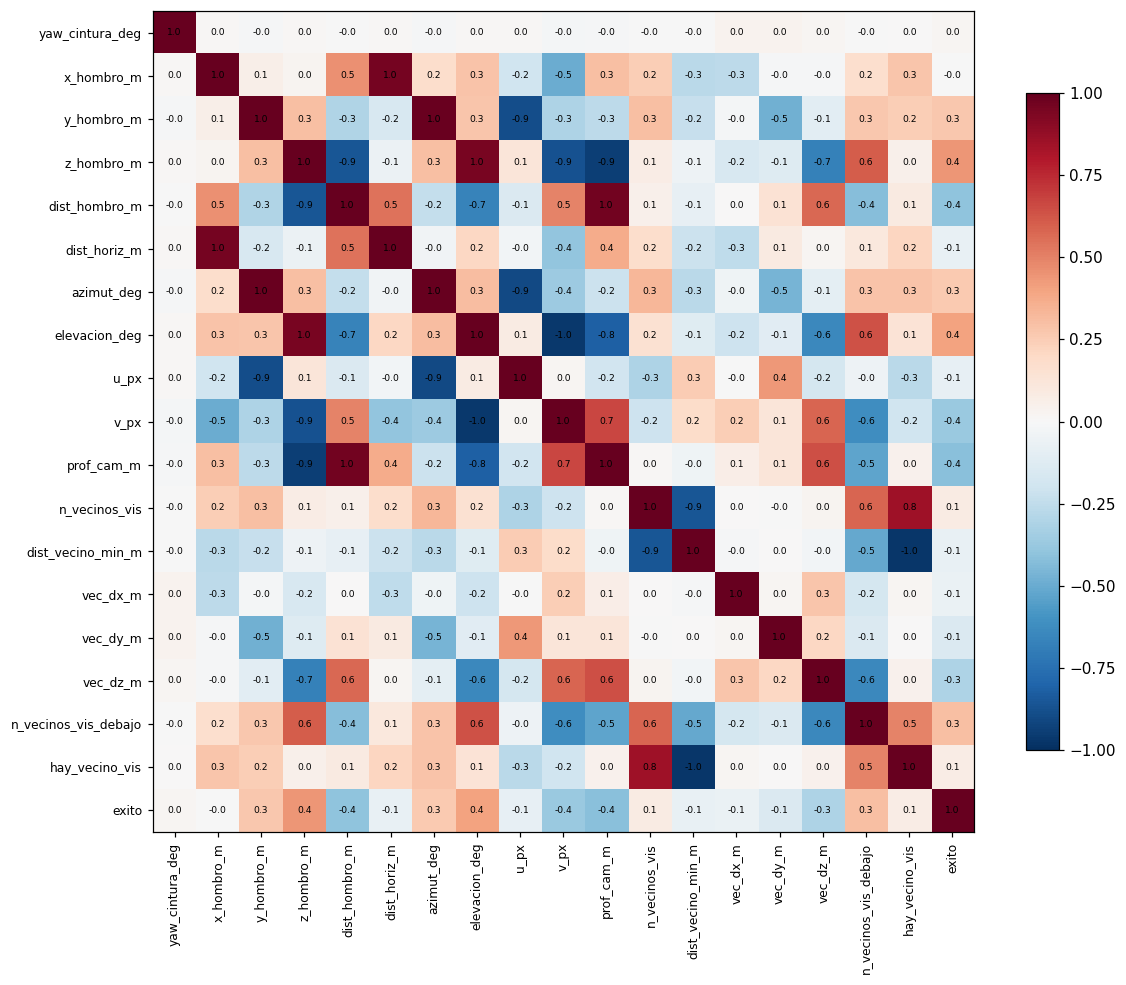

Correlación de cada entrada con el éxito:
z_hombro_m              0.438
prof_cam_m             -0.418
elevacion_deg           0.401
dist_hombro_m          -0.401
v_px                   -0.373
vec_dz_m               -0.308
n_vecinos_vis_debajo    0.303
y_hombro_m              0.269
azimut_deg              0.263
vec_dy_m               -0.148
u_px                   -0.085
n_vecinos_vis           0.085
dist_vecino_min_m      -0.078
dist_horiz_m           -0.076
hay_vecino_vis          0.072
vec_dx_m               -0.068
yaw_cintura_deg         0.017
x_hombro_m             -0.005


In [8]:
corr = df[ENTRADAS + ["exito"]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.grid(False)
guardar("correlaciones")
plt.show()
print("Correlación de cada entrada con el éxito:")
print(corr["exito"].drop("exito").sort_values(key=np.abs, ascending=False).round(3).to_string())

Varias entradas son redundantes por construcción (por ejemplo `dist_hombro_m` con `dist_horiz_m`, o el píxel
`v_px` con la altura): describen la misma posición en otros sistemas de coordenadas. Los modelos lineales sufren
con la colinealidad, por eso se usa regularización; los árboles no se ven afectados.

### 2.4 Tipo de entrenamiento

Cada intento tiene su **respuesta real** (la simulación registra si la manzana llegó a la canasta y, si no, en
qué etapa falló). Hay retroalimentación completa, por lo tanto el aprendizaje es **supervisado**, y la salida
es categórica: **clasificación** (binaria y multiclase).

## 3. Definición de los modelos

Se eligen modelos de `scikit-learn` de naturalezas distintas:

| modelo | por qué |
|---|---|
| Regresión logística (L2) | línea de base interpretable; probabilidades bien calibradas |
| k vecinos más cercanos (k-NN) | el éxito depende de la zona del espacio de trabajo: manzanas parecidas tienen resultados parecidos |
| Máquina de vectores de soporte (kernel RBF) | frontera no lineal suave (el espacio alcanzable del brazo es curvo) |
| Bosque aleatorio | interacciones entre variables (altura × vecinos), robusto a la colinealidad |
| Gradient boosting | suele ser el más preciso en datos tabulares; permite ver el desempeño por iteración ("épocas") |

Además, un **clasificador trivial** (siempre la clase más frecuente) como referencia mínima.

**Partición:** la corrida de la semilla 1 es el **conjunto de prueba**
(intentos simulados en una corrida independiente: validación en simulación); las demás semillas son el
entrenamiento. Si no hay datos de la semilla 1, se usa un 20 % estratificado. Los
hiperparámetros se eligen con validación cruzada estratificada de 5 particiones **solo** sobre el
entrenamiento.

In [9]:
semillas = sorted(df.semilla.unique())
SEMILLA_TEST = int(os.environ.get("ML_SEMILLA_TEST", 1))     # la corrida reservada para la prueba
if len(semillas) > 1 and SEMILLA_TEST in semillas:
    train, test = df[df.semilla != SEMILLA_TEST], df[df.semilla == SEMILLA_TEST]
    print(f"prueba = corrida independiente (semilla {SEMILLA_TEST})")
else:
    train, test = train_test_split(df, test_size=0.2, stratify=df.exito, random_state=SEED)
    print("prueba = 20 % estratificado")
X_tr, X_te = train[ENTRADAS].values, test[ENTRADAS].values
y_tr, y_te = train.exito.values, test.exito.values
print(f"entrenamiento {len(train)} (éxito {y_tr.mean():.1%}), prueba {len(test)} (éxito {y_te.mean():.1%})")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

prueba = corrida independiente (semilla 1)
entrenamiento 1971 (éxito 35.7%), prueba 592 (éxito 42.2%)


In [10]:
def pipe(modelo):
    return Pipeline([("escala", StandardScaler()), ("modelo", modelo)])

MODELOS = {
    "Trivial": (pipe(DummyClassifier(strategy="most_frequent")), {}),
    "Regresión logística": (pipe(LogisticRegression(max_iter=2000)),
                            {"modelo__C": [0.01, 0.1, 1, 10, 100]}),
    "k-NN": (pipe(KNeighborsClassifier()),
             {"modelo__n_neighbors": [5, 11, 21, 41], "modelo__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (pipe(SVC(kernel="rbf", probability=True, random_state=SEED)),
                  {"modelo__C": [0.3, 1, 3, 10], "modelo__gamma": ["scale", 0.03, 0.1]}),
    "Bosque aleatorio": (pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
                         {"modelo__max_depth": [4, 8, None], "modelo__min_samples_leaf": [1, 5, 20]}),
    "Gradient boosting": (pipe(GradientBoostingClassifier(random_state=SEED)),
                          {"modelo__n_estimators": [100, 300], "modelo__learning_rate": [0.03, 0.1],
                           "modelo__max_depth": [2, 3]}),
}

ajustados = {}
for nombre, (est, grid) in MODELOS.items():
    gs = GridSearchCV(est, grid or {"escala": [StandardScaler()]}, scoring="roc_auc", cv=CV, n_jobs=-1)
    gs.fit(X_tr, y_tr)
    ajustados[nombre] = gs
    print(f"{nombre:22s} AUC-VC {gs.best_score_:.3f}   {gs.best_params_ if grid else ''}")

Trivial                AUC-VC 0.500   


Regresión logística    AUC-VC 0.802   {'modelo__C': 100}
k-NN                   AUC-VC 0.816   {'modelo__n_neighbors': 41, 'modelo__weights': 'distance'}


SVM (RBF)              AUC-VC 0.819   {'modelo__C': 1, 'modelo__gamma': 'scale'}


Bosque aleatorio       AUC-VC 0.843   {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 5}


Gradient boosting      AUC-VC 0.835   {'modelo__learning_rate': 0.1, 'modelo__max_depth': 2, 'modelo__n_estimators': 300}


## 4. Análisis comparativo — salida binaria (¿llega a la canasta?)

**Métricas elegidas y por qué:**

* **Exactitud** (*accuracy*): proporción de aciertos; fácil de leer, pero engañosa si las clases están
  desbalanceadas (por eso se compara contra el clasificador trivial).
* **Precisión** de la clase éxito: de los intentos que el modelo aprueba, cuántos salen bien — es lo que
  importa si el robot solo intenta las manzanas aprobadas.
* **Exhaustividad** (*recall*): de las manzanas cosechables, cuántas aprueba (las no aprobadas se pierden).
* **F1**: media armónica de las dos anteriores.
* **AUC-ROC**: calidad del ordenamiento por probabilidad, sin depender de un umbral — sirve para elegir qué
  manzana intentar primero.
* **Brier**: error cuadrático medio de la probabilidad predicha (calibración).
* **Intervalo de confianza del 95 %** de la exactitud y el AUC, por *bootstrap* del conjunto de prueba (1000
  remuestreos), para saber si las diferencias entre modelos son reales o ruido.

In [11]:
rng = np.random.default_rng(SEED)
B = rng.integers(0, len(y_te), size=(1000, len(y_te)))

def ic95(fn, y, p):
    vals = []
    for b in B:
        if len(np.unique(y[b])) < 2:
            continue
        vals.append(fn(y[b], p[b]))
    return np.percentile(vals, [2.5, 97.5])

filas, PROBA = [], {}
for nombre, gs in ajustados.items():
    p = gs.predict_proba(X_te)[:, 1]
    yhat = (p >= 0.5).astype(int)
    PROBA[nombre] = p
    auc = roc_auc_score(y_te, p) if nombre != "Trivial" else 0.5
    a_lo, a_hi = ic95(lambda y, q: accuracy_score(y, q >= 0.5), y_te, p)
    u_lo, u_hi = ic95(roc_auc_score, y_te, p) if nombre != "Trivial" else (0.5, 0.5)
    filas.append({"modelo": nombre, "exactitud": accuracy_score(y_te, yhat), "IC95 exactitud": f"[{a_lo:.3f}, {a_hi:.3f}]",
                  "precisión": precision_score(y_te, yhat, zero_division=0),
                  "exhaustividad": recall_score(y_te, yhat, zero_division=0),
                  "F1": f1_score(y_te, yhat, zero_division=0), "AUC-ROC": auc, "IC95 AUC": f"[{u_lo:.3f}, {u_hi:.3f}]",
                  "Brier": brier_score_loss(y_te, p), "AUC-VC (entren.)": gs.best_score_})
res_bin = pd.DataFrame(filas).set_index("modelo").round(3)
res_bin.to_csv(os.path.join(FIG, "tabla_binaria.csv"))
res_bin

,exactitud,IC95 exactitud,precisión,exhaustividad,F1,AUC-ROC,IC95 AUC,Brier,AUC-VC (entren.)
modelo,,,,,,,,,
Trivial,0.578,"[0.537, 0.617]",0.000,0.000,0.000,0.500,"[0.500, 0.500]",0.422,0.500
Regresión logística,0.666,"[0.627, 0.704]",0.626,0.516,0.566,0.747,"[0.704, 0.785]",0.204,0.802
k-NN,0.704,"[0.666, 0.742]",0.667,0.600,0.632,0.772,"[0.733, 0.809]",0.195,0.816
SVM (RBF),0.682,"[0.644, 0.720]",0.667,0.496,0.569,0.780,"[0.742, 0.818]",0.200,0.819
Bosque aleatorio,0.718,"[0.681, 0.752]",0.684,0.616,0.648,0.814,"[0.780, 0.847]",0.174,0.843
Gradient boosting,0.686,"[0.647, 0.723]",0.650,0.556,0.599,0.796,"[0.759, 0.830]",0.185,0.835


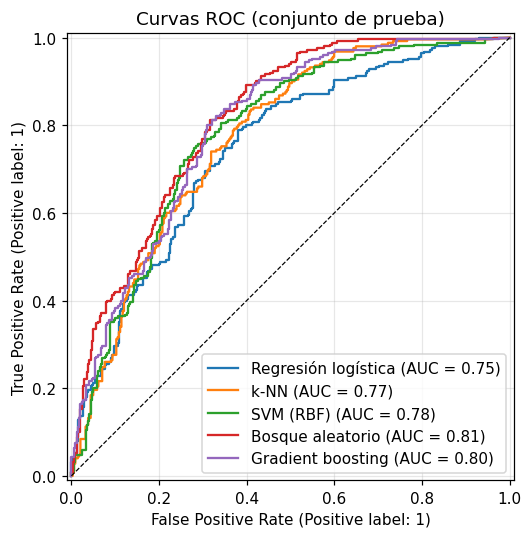

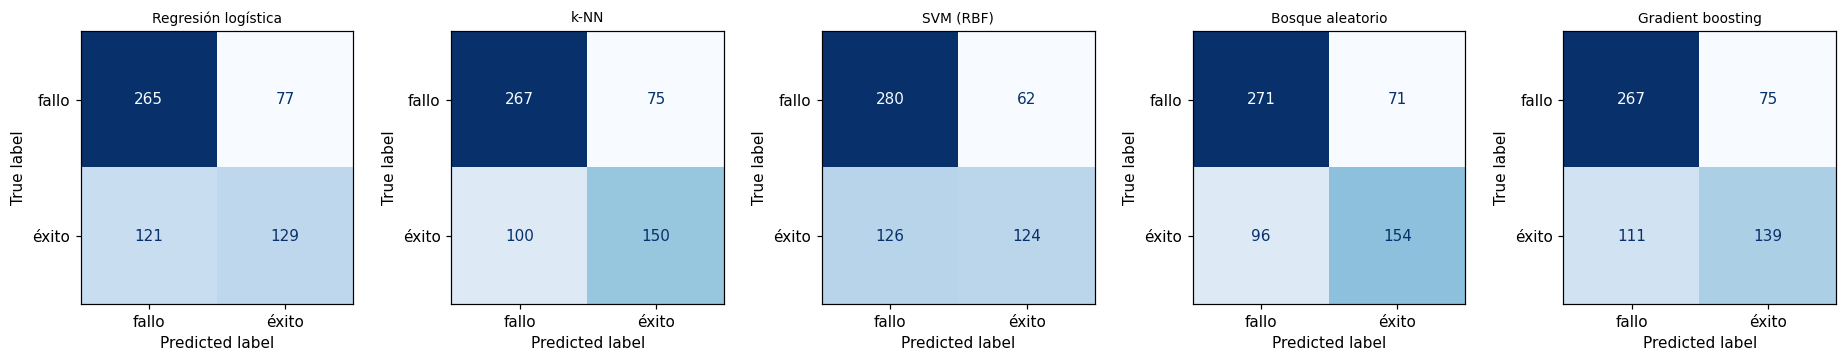

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
for nombre, p in PROBA.items():
    if nombre != "Trivial":
        RocCurveDisplay.from_predictions(y_te, p, name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_title("Curvas ROC (conjunto de prueba)")
guardar("roc")
plt.show()

nombres = [n for n in ajustados if n != "Trivial"]
fig, axs = plt.subplots(1, len(nombres), figsize=(3.4 * len(nombres), 3.2))
for ax, nombre in zip(axs, nombres):
    ConfusionMatrixDisplay.from_predictions(y_te, (PROBA[nombre] >= 0.5).astype(int), display_labels=["fallo", "éxito"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre, fontsize=9); ax.grid(False)
guardar("confusion_binaria")
plt.show()

### 4.1 Desempeño según la cantidad de datos y las "épocas" de entrenamiento

* **Curva de aprendizaje:** AUC en validación cruzada al entrenar con el 10 % … 100 % del conjunto de
  entrenamiento. Indica si conviene simular más intentos.
* **Gradient boosting por iteración:** cada árbol nuevo es una "época"; se muestra el AUC en entrenamiento y en
  prueba después de cada árbol (sobreajuste cuando las curvas se separan).

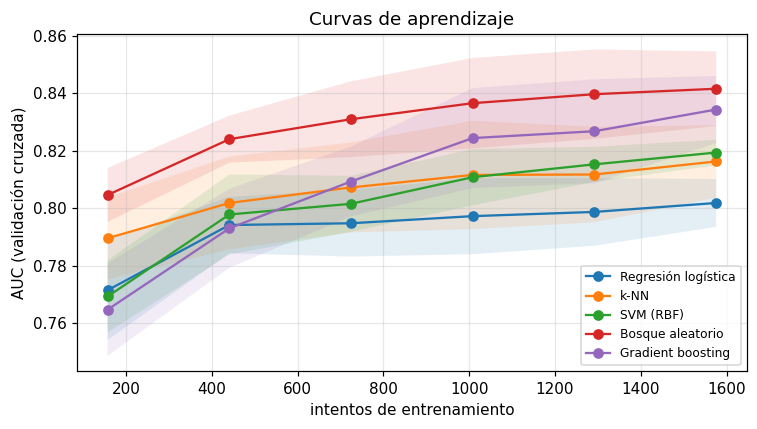

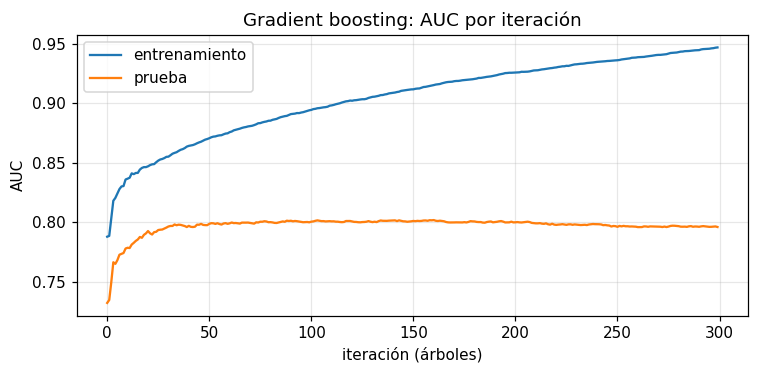

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
for nombre in nombres:
    tam, tr, va = learning_curve(ajustados[nombre].best_estimator_, X_tr, y_tr, cv=CV, scoring="roc_auc",
                                 train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=SEED, shuffle=True)
    ax.plot(tam, va.mean(1), "o-", label=nombre)
    ax.fill_between(tam, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.12)
ax.set_xlabel("intentos de entrenamiento"); ax.set_ylabel("AUC (validación cruzada)")
ax.set_title("Curvas de aprendizaje"); ax.legend(fontsize=8)
guardar("curvas_aprendizaje")
plt.show()

gb = ajustados["Gradient boosting"].best_estimator_
Xs_tr, Xs_te = gb[:-1].transform(X_tr), gb[:-1].transform(X_te)
auc_tr = [roc_auc_score(y_tr, p[:, 1]) for p in gb[-1].staged_predict_proba(Xs_tr)]
auc_te = [roc_auc_score(y_te, p[:, 1]) for p in gb[-1].staged_predict_proba(Xs_te)]
plt.figure(figsize=(7, 3.5))
plt.plot(auc_tr, label="entrenamiento"); plt.plot(auc_te, label="prueba")
plt.xlabel("iteración (árboles)"); plt.ylabel("AUC"); plt.title("Gradient boosting: AUC por iteración"); plt.legend()
guardar("gb_iteraciones")
plt.show()

### 4.2 ¿Qué variables usa el mejor modelo?

Importancia por permutación en el conjunto de prueba: cuánto cae el AUC al desordenar cada variable.

mejor modelo por AUC en prueba: Bosque aleatorio


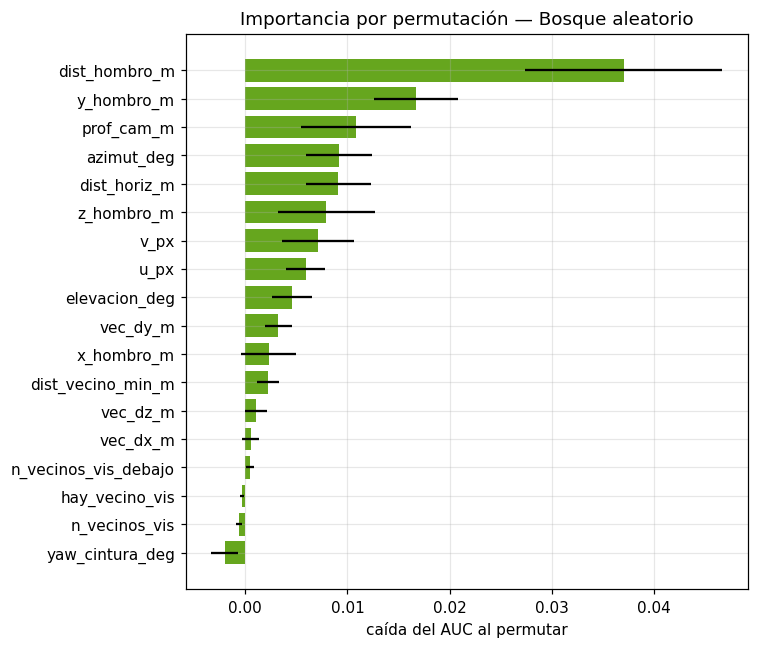

In [14]:
mejor = res_bin.drop("Trivial")["AUC-ROC"].idxmax()
print("mejor modelo por AUC en prueba:", mejor)
pi = permutation_importance(ajustados[mejor].best_estimator_, X_te, y_te, scoring="roc_auc", n_repeats=20,
                            random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=ENTRADAS).sort_values()
plt.figure(figsize=(7, 6))
plt.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=ENTRADAS)[imp.index], color="#66a61e")
plt.xlabel("caída del AUC al permutar"); plt.title(f"Importancia por permutación — {mejor}")
guardar("importancia")
plt.show()

### 4.3 Uso práctico: intentar solo las manzanas aprobadas

Regla de decisión: el robot intenta una manzana solo si la probabilidad predicha de éxito supera un umbral.
Sobre los intentos de prueba (simulados de forma independiente) se mide la tasa de éxito de los intentos que se
harían y la fracción de manzanas que se dejarían sin intentar. Con umbral 0 el robot intenta todo (situación
actual).

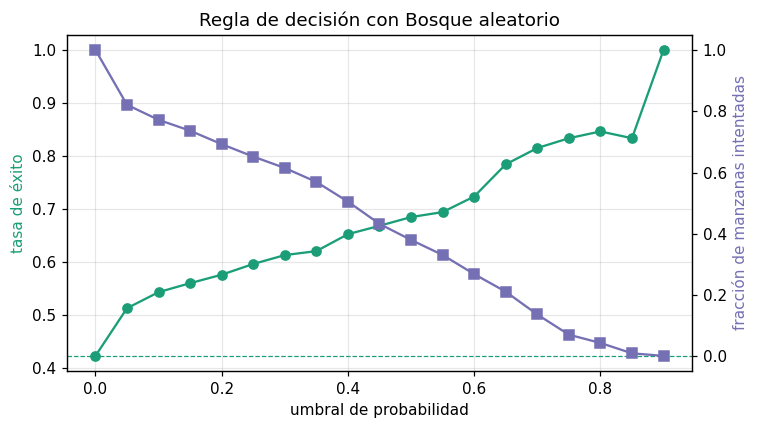

,umbral,éxito de intentos,intentadas
0,0.0,0.422,1.000
2,0.1,0.543,0.772
4,0.2,0.576,0.693
6,0.3,0.613,0.615
8,0.4,0.652,0.505
10,0.5,0.684,0.380
12,0.6,0.723,0.269
14,0.7,0.815,0.137
16,0.8,0.846,0.044
18,0.9,1.000,0.002


In [15]:
p = PROBA[mejor]
umbrales = np.linspace(0, 0.9, 19)
tasa, frac = [], []
for u in umbrales:
    m = p >= u
    tasa.append(y_te[m].mean() if m.any() else np.nan)
    frac.append(m.mean())
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(umbrales, tasa, "o-", color="#1b9e77", label="éxito de los intentos hechos")
ax1.axhline(y_te.mean(), color="#1b9e77", ls="--", lw=0.8)
ax1.set_xlabel("umbral de probabilidad"); ax1.set_ylabel("tasa de éxito", color="#1b9e77")
ax2 = ax1.twinx()
ax2.plot(umbrales, frac, "s-", color="#7570b3"); ax2.set_ylabel("fracción de manzanas intentadas", color="#7570b3")
ax2.grid(False)
plt.title(f"Regla de decisión con {mejor}")
guardar("regla_decision")
plt.show()
pd.DataFrame({"umbral": umbrales, "éxito de intentos": np.round(tasa, 3), "intentadas": np.round(frac, 3)})[::2]

## 5. Análisis comparativo — salida multiclase (¿en qué etapa falla?)

Clases: `exito`, `alcance` (la mano no llegó a la manzana), `agarre` (no quedó nada entre los dedos),
`desprendimiento` (el pedúnculo resistió o la fruta se resbaló al tirar), `retorno` (se cayó al volver),
`transporte` (se cayó camino a la canasta), `deposito` (cayó fuera de la canasta) y `tiempo`.
Las clases con menos del 3 % de los intentos se agrupan en `otro` porque no hay ejemplos suficientes para
aprenderlas.

Las clases están desbalanceadas, así que se usan pesos de clase balanceados y las métricas son la **F1
macro** (promedio sin ponderar de la F1 de cada clase: una clase rara cuenta igual que una frecuente) y la
**exactitud balanceada** (promedio de la exhaustividad por clase).

In [16]:
frec = df.etapa.value_counts(normalize=True)
raras = frec[frec < 0.03].index.tolist()
df["etapa_m"] = df.etapa.where(~df.etapa.isin(raras), "otro")
train_m, test_m = df.loc[train.index], df.loc[test.index]
z_tr, z_te = train_m.etapa_m.values, test_m.etapa_m.values
CLASES = [c for c in ["exito", "alcance", "agarre", "desprendimiento", "retorno", "transporte", "deposito",
                      "tiempo", "otro"] if c in set(df.etapa_m)]
print("agrupadas en 'otro':", raras or "ninguna")
print(train_m.etapa_m.value_counts().to_string())

MODELOS_M = {
    "Trivial": (pipe(DummyClassifier(strategy="most_frequent")), {}),
    "Regresión logística": (pipe(LogisticRegression(max_iter=3000, class_weight="balanced")),
                            {"modelo__C": [0.01, 0.1, 1, 10]}),
    "k-NN": (pipe(KNeighborsClassifier()), {"modelo__n_neighbors": [5, 11, 21], "modelo__weights": ["distance"]}),
    "SVM (RBF)": (pipe(SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
                  {"modelo__C": [0.3, 1, 3, 10], "modelo__gamma": ["scale", 0.1]}),
    "Bosque aleatorio": (pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                     random_state=SEED, n_jobs=-1)),
                         {"modelo__max_depth": [6, 12, None], "modelo__min_samples_leaf": [1, 5]}),
    "Gradient boosting": (pipe(GradientBoostingClassifier(random_state=SEED)),
                          {"modelo__n_estimators": [100, 300], "modelo__learning_rate": [0.05, 0.1],
                           "modelo__max_depth": [2, 3]}),
}
filas, PRED_M, ajust_m = [], {}, {}
for nombre, (est, grid) in MODELOS_M.items():
    gs = GridSearchCV(est, grid or {"escala": [StandardScaler()]}, scoring="f1_macro", cv=CV, n_jobs=-1)
    gs.fit(X_tr, z_tr)
    ajust_m[nombre] = gs
    zhat = gs.predict(X_te)
    PRED_M[nombre] = zhat
    filas.append({"modelo": nombre, "exactitud": accuracy_score(z_te, zhat),
                  "exactitud balanceada": balanced_accuracy_score(z_te, zhat),
                  "F1 macro": f1_score(z_te, zhat, average="macro", zero_division=0),
                  "F1 macro VC (entren.)": gs.best_score_})
res_multi = pd.DataFrame(filas).set_index("modelo").round(3)
res_multi.to_csv(os.path.join(FIG, "tabla_multiclase.csv"))
res_multi

agrupadas en 'otro': ['retorno', 'deposito']
etapa_m
exito              704
agarre             548
desprendimiento    389
alcance            185
transporte          99
otro                46


,exactitud,exactitud balanceada,F1 macro,F1 macro VC (entren.)
modelo,,,,
Trivial,0.422,0.167,0.099,0.088
Regresión logística,0.414,0.464,0.412,0.419
k-NN,0.574,0.388,0.385,0.409
SVM (RBF),0.476,0.447,0.424,0.457
Bosque aleatorio,0.591,0.464,0.461,0.497
Gradient boosting,0.627,0.454,0.455,0.480


mejor modelo multiclase: Bosque aleatorio
                 precision    recall  f1-score   support

          exito       0.64      0.68      0.66       250
        alcance       0.92      0.95      0.93        37
         agarre       0.67      0.67      0.67       152
desprendimiento       0.45      0.38      0.41       107
     transporte       0.08      0.11      0.09        28
           otro       0.00      0.00      0.00        18

       accuracy                           0.59       592
      macro avg       0.46      0.46      0.46       592
   weighted avg       0.59      0.59      0.59       592



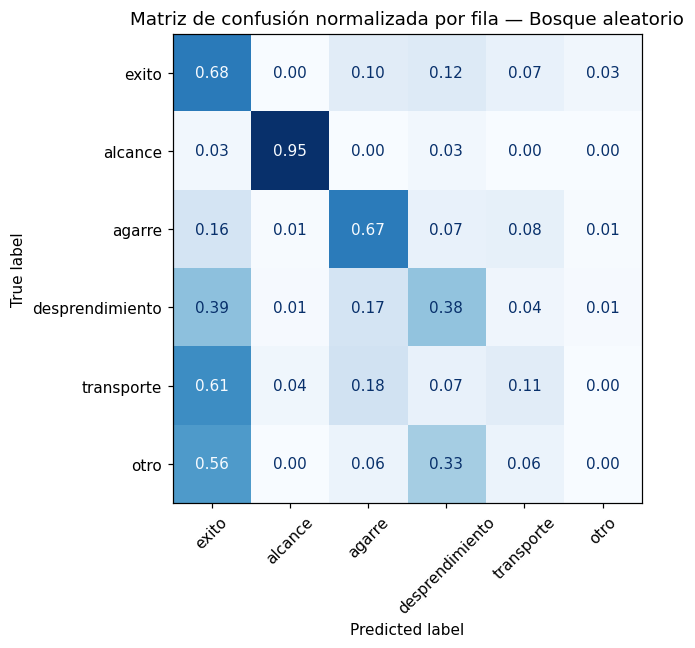

In [17]:
mejor_m = res_multi.drop("Trivial")["F1 macro"].idxmax()
print("mejor modelo multiclase:", mejor_m)
print(classification_report(z_te, PRED_M[mejor_m], labels=CLASES, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(z_te, PRED_M[mejor_m], labels=CLASES, normalize="true", ax=ax,
                                        cmap="Blues", values_format=".2f", colorbar=False)
ax.set_title(f"Matriz de confusión normalizada por fila — {mejor_m}"); ax.grid(False)
plt.xticks(rotation=45)
guardar("confusion_multiclase")
plt.show()

## 6. Conclusiones

*(Completar con los números obtenidos. Guía:)*

* ¿Qué modelo ordena mejor los intentos (AUC) y qué tan lejos está del clasificador trivial? ¿Los intervalos
  de confianza de los mejores modelos se solapan?
* ¿Qué variables pesan más (importancia por permutación)? ¿Coincide con lo observado en el robot real (las
  manzanas bajas casi nunca se cosechaban)?
* ¿La curva de aprendizaje sigue subiendo (conviene simular más) o ya se estabilizó?
* Multiclase: ¿qué etapas se distinguen bien y cuáles se confunden? Las caídas durante el transporte dependen
  de la calidad del agarre, que no se conoce antes de intentar: es esperable que sean difíciles de predecir.
* **Limitaciones:** datos solo de simulación (la física del agarre y del pedúnculo es aproximada); la visibilidad
  de los vecinos no considera oclusiones entre manzanas; no se usa la distancia al tronco; el modelo vale para
  estas políticas (si se reentrena el brazo, hay que volver a recolectar datos); no hubo validación en el robot
  real.

In [18]:
print("Resumen binario (prueba):")
print(res_bin[["exactitud", "F1", "AUC-ROC", "IC95 AUC", "Brier"]].to_string())
print("\nResumen multiclase (prueba):")
print(res_multi.to_string())

Resumen binario (prueba):
                     exactitud     F1  AUC-ROC        IC95 AUC  Brier
modelo                                                               
Trivial                  0.578  0.000    0.500  [0.500, 0.500]  0.422
Regresión logística      0.666  0.566    0.747  [0.704, 0.785]  0.204
k-NN                     0.704  0.632    0.772  [0.733, 0.809]  0.195
SVM (RBF)                0.682  0.569    0.780  [0.742, 0.818]  0.200
Bosque aleatorio         0.718  0.648    0.814  [0.780, 0.847]  0.174
Gradient boosting        0.686  0.599    0.796  [0.759, 0.830]  0.185

Resumen multiclase (prueba):
                     exactitud  exactitud balanceada  F1 macro  F1 macro VC (entren.)
modelo                                                                               
Trivial                  0.422                 0.167     0.099                  0.088
Regresión logística      0.414                 0.464     0.412                  0.419
k-NN                     0.574          